### **Telecom Customer Churn Prediction**

#### **.** Problem Statement
Customer churn (customers leaving the service) costs telecom companies far more than retaining existing customers. The goal is to identify customers who are likely to churn so the company can offer them retention deals in time.

#### **.** Objective
Build an end-to-end machine learning pipeline that predicts whether a customer will churn, optimised to catch as many churners as possible (high recall), and deploy it as a web app.

#### **.** Dataset
IBM Telco Customer Churn dataset: 7,043 customers, 21 columns (demographics, services, contract, billing). About 26.5% of customers churned, so the data is imbalanced.

#### **.** Technologies Used
Python, pandas, NumPy, Matplotlib, Seaborn, scikit-learn, XGBoost, joblib, Streamlit

#### **.** Approach
1. Data cleaning and exploratory data analysis
2. Feature engineering (TenureGroup, TotalServices)
3. Stratified train/test split, preprocessing with Pipeline + ColumnTransformer (no data leakage)
4. Model comparison: Logistic Regression (baseline), Random Forest and XGBoost, each with and without class weights
5. Hyperparameter tuning (RandomizedSearchCV) and decision-threshold tuning on out-of-fold predictions
6. Final evaluation on a held-out test set, feature importance, model saved with joblib

#### **.** Final Result (test set, XGBoost, threshold 0.55)
Recall 0.76 | Precision 0.54 | F1 0.63 | ROC-AUC 0.848

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    RandomizedSearchCV,
    cross_val_predict
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


#### **1. Data Understanding**

In [5]:
df.shape

(7043, 21)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [8]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [9]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [10]:
pd.to_numeric(df['TotalCharges'], errors='coerce').isnull().sum()

np.int64(11)

In [11]:
df[pd.to_numeric(df['TotalCharges'], errors='coerce').isnull()][['customerID', 'tenure', 'TotalCharges']]

,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


#### **2. Data Cleaning**

In [12]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [13]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [14]:
df['TotalCharges'].dtype, df['TotalCharges'].isnull().sum()

(dtype('float64'), np.int64(0))

In [15]:
df = df.drop('customerID', axis=1)

In [16]:
df['Churn'] = df['Churn'].map({'Yes':1, 'No':0})

In [17]:
df.duplicated().sum()

np.int64(22)

In [18]:
df.shape

(7043, 20)

#### **3. Exploratory Data Analysis**

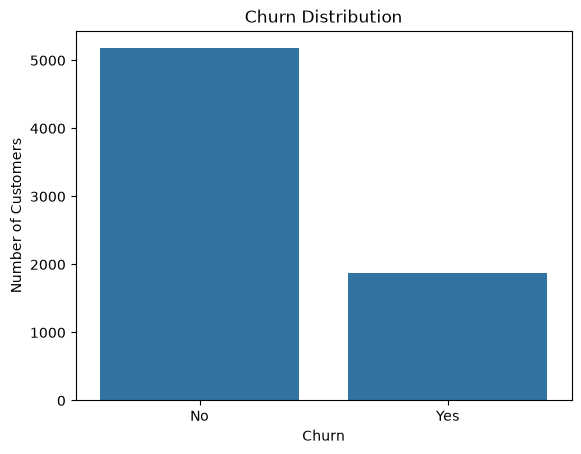

In [19]:
# churn distribution

sns.countplot(x='Churn', data=df)
plt.title('Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.xticks([0, 1], ['No', 'Yes'])
plt.show()

**Insight:** Out of 7,043 customers, 1,869 (about 26.5%) churned and 5,174 stayed. The dataset is imbalanced, so accuracy alone will be misleading and we will focus on recall and F1-score.

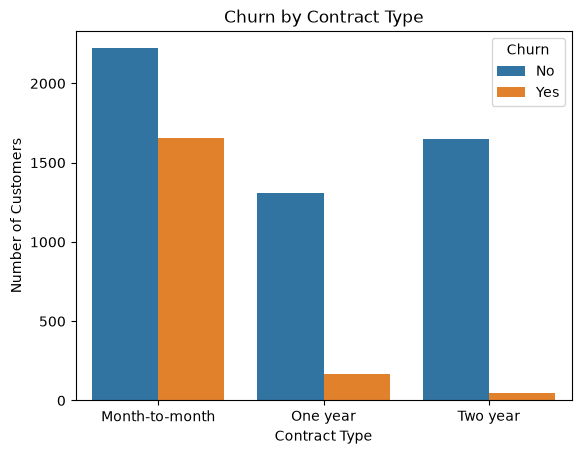

In [20]:
# contract vs churn 

sns.countplot(x='Contract', hue='Churn', data=df)
plt.title('Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.legend(title='Churn', labels=['No', 'Yes'])
plt.show()

**Insight:** Customers on month-to-month contracts churn far more than customers on one-year or two-year contracts. Longer contracts are associated with better retention.

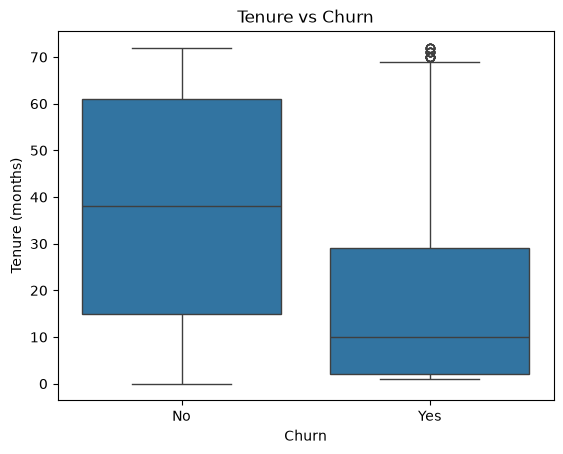

In [21]:
# tenure vs churn 

sns.boxplot(x='Churn', y='tenure', data=df)
plt.title('Tenure vs Churn')
plt.xlabel('Churn')
plt.ylabel('Tenure (months)')
plt.xticks([0, 1], ['No', 'Yes'])
plt.show()

**Insight:** Customers who churn have a much lower median tenure (about 10 months) than those who stay (about 38 months). New customers are at the highest risk of churning.

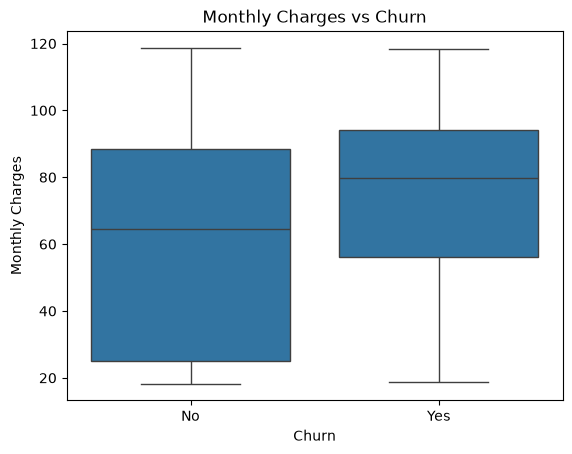

In [22]:
sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.title('Monthly Charges vs Churn')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.xticks([0, 1], ['No', 'Yes'])
plt.show()

**Insight:** Customers who churn tend to have higher monthly charges than customers who stay.

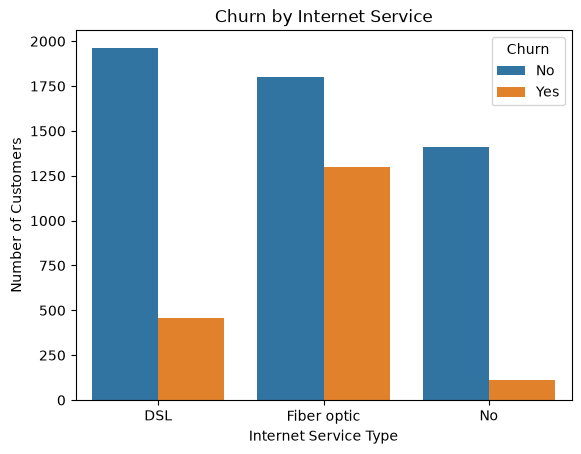

In [23]:
sns.countplot(x='InternetService', hue='Churn', data=df)
plt.title('Churn by Internet Service')
plt.xlabel('Internet Service Type')
plt.ylabel('Number of Customers')
plt.legend(title='Churn', labels=['No', 'Yes'])
plt.show()

**Insight:** Fiber optic customers show a higher churn rate than DSL customers or customers with no internet service.

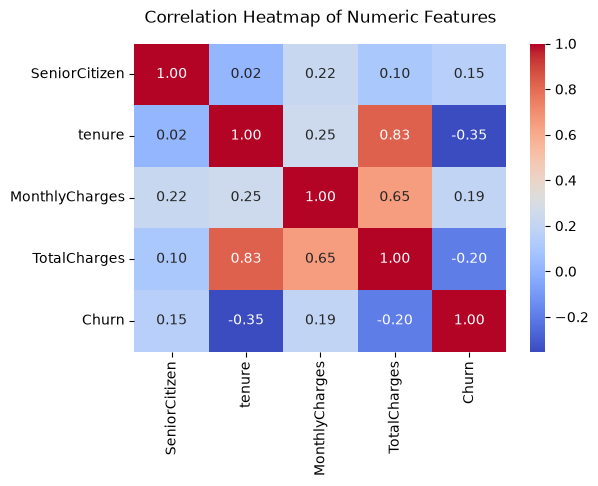

In [24]:
corr = df.select_dtypes(include='number').corr()

plt.figure(figsize=(6,4))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numeric Features', pad=15)
plt.show()

**Insight:** Tenure has the strongest (negative) correlation with churn (-0.35): the longer a customer stays, the less likely they are to churn. MonthlyCharges (0.19) and SeniorCitizen (0.15) show only a weak positive relationship with churn. Tenure and TotalCharges are highly correlated (0.83), which is expected because TotalCharges accumulates over time. No single numeric feature is strongly linked to churn, so categorical features such as Contract type matter more.

#### **4. Feature Engineering**

In [25]:
df['TenureGroup'] = pd.cut(df['tenure'], bins=[-1, 12, 24, 36, 48, 60, 72], labels=['0-12', '13-24', '25-36', '37-48', '49-60', '61-72'])

In [26]:
service_cols = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
df['TotalServices'] = (df[service_cols] == 'Yes').sum(axis=1)   

In [27]:
df[['tenure', 'TenureGroup', 'TotalServices']].head()

,tenure,TenureGroup,TotalServices
0,1,0-12,1
1,34,25-36,3
2,2,0-12,3
3,45,37-48,3
4,2,0-12,1


#### **5. Train-Test Split**

In [28]:
X = df.drop('Churn', axis= 1)
y = df['Churn']

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

In [30]:
print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

(5634, 21) (1409, 21)
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


#### **6. Preprocessing Pipeline**

In [31]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'TotalServices']
binary_cols = ['SeniorCitizen']
cat_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
            'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
            'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
            'PaperlessBilling', 'PaymentMethod', 'TenureGroup']

In [32]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

In [33]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_cols),
        ('cat', categorical_transformer, cat_cols)
    ],
    remainder='passthrough'
)

In [34]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(X_train_processed.shape, X_test_processed.shape)

(5634, 52) (1409, 52)


####  **7. Baseline Model: Logistic Regression**

In [35]:
model = LogisticRegression(max_iter=10000, random_state=42)
model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

In [36]:
y_pred = model.predict(X_test_processed)
y_proba = model.predict_proba(X_test_processed)[:, 1]

In [37]:
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.66      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.80      1409

[[934 101]
 [177 197]]


In [38]:
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.3f}")

ROC-AUC: 0.843


**Insight:** The baseline Logistic Regression reaches 80% accuracy and a ROC-AUC of 0.843, but its recall for churners is only 0.53, so it misses almost half of the customers who actually leave. Because the data is imbalanced, accuracy alone is misleading and we will focus on recall, F1 and ROC-AUC.

##### 7.1 Random Forest (without class weights)

In [39]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train_processed, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total nu

In [40]:
y_pred_rf = rf.predict(X_test_processed)
y_proba_rf = rf.predict_proba(X_test_processed)[:, 1]

In [41]:
print(classification_report(y_test, y_pred_rf))
print(confusion_matrix(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1035
           1       0.66      0.50      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.70      0.72      1409
weighted avg       0.79      0.80      0.79      1409

[[940  95]
 [188 186]]


In [42]:
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_rf):.3f}")

ROC-AUC: 0.842


##### 7.2 XGBoost (without class weights)

In [43]:
xgb = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)
xgb.fit(X_train_processed, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [44]:
y_pred_xgb = xgb.predict(X_test_processed)
y_proba_xgb = xgb.predict_proba(X_test_processed)[:, 1]

In [45]:
print(classification_report(y_test, y_pred_xgb))
print(confusion_matrix(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.67      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.76      0.71      0.73      1409
weighted avg       0.79      0.80      0.80      1409

[[941  94]
 [181 193]]


In [46]:
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_xgb):.3f}")

ROC-AUC: 0.845


#### **8. Handling Class Imbalance**

##### Logistic Regression (with class weights)

In [47]:
model_balanced = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
model_balanced.fit(X_train_processed, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [48]:
y_pred_bal = model_balanced.predict(X_test_processed)
y_proba_bal = model_balanced.predict_proba(X_test_processed)[:, 1]

In [49]:
print(classification_report(y_test, y_pred_bal))
print(confusion_matrix(y_test, y_pred_bal))

              precision    recall  f1-score   support

           0       0.91      0.72      0.80      1035
           1       0.51      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409

[[745 290]
 [ 76 298]]


In [50]:
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_bal):.3f}")

ROC-AUC: 0.843


**Insight:** Using class_weight='balanced' raised the recall for churners from 0.53 to 0.80, so the model now catches many more customers who are about to leave. The cost is lower precision (0.51), meaning more false alarms. ROC-AUC stays at 0.843 because class weights shift the decision boundary, not the ranking quality of the model.

##### 8.1 Random Forest (with class weights)

In [51]:
rf_bal = RandomForestClassifier(
    n_estimators=200, max_depth=8, min_samples_leaf=5,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_bal.fit(X_train_processed, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_featu

In [52]:
y_pred_rf_bal = rf_bal.predict(X_test_processed)
y_proba_rf_bal = rf_bal.predict_proba(X_test_processed)[:, 1]

In [53]:
print(classification_report(y_test, y_pred_rf_bal))
print(confusion_matrix(y_test, y_pred_rf_bal))

              precision    recall  f1-score   support

           0       0.91      0.73      0.81      1035
           1       0.52      0.80      0.63       374

    accuracy                           0.75      1409
   macro avg       0.72      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409

[[759 276]
 [ 75 299]]


In [54]:
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_rf_bal):.3f}")

ROC-AUC: 0.842


##### 8.2 XGBoost (with scale_pos_weight)

In [55]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {spw:.2f}")

scale_pos_weight = 2.77


In [56]:
xgb_bal = XGBClassifier(
    n_estimators=200, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
    eval_metric='logloss', random_state=42, n_jobs=-1
)
xgb_bal.fit(X_train_processed, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [57]:
y_pred_xgb_bal = xgb_bal.predict(X_test_processed)
y_proba_xgb_bal = xgb_bal.predict_proba(X_test_processed)[:, 1]

In [58]:
print(classification_report(y_test, y_pred_xgb_bal))
print(confusion_matrix(y_test, y_pred_xgb_bal))

              precision    recall  f1-score   support

           0       0.91      0.74      0.82      1035
           1       0.53      0.79      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.72      1409
weighted avg       0.81      0.76      0.77      1409

[[770 265]
 [ 79 295]]


In [59]:
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_xgb_bal):.3f}")

ROC-AUC: 0.845


#### **9.Model Comparison**

In [60]:
def evaluate(name, y_true, y_pred, y_proba):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_proba),
    }

In [61]:
results = []
results.append(evaluate('LogReg (plain)',    y_test, y_pred,         y_proba))
results.append(evaluate('LogReg (balanced)', y_test, y_pred_bal,     y_proba_bal))
results.append(evaluate('RF (plain)',        y_test, y_pred_rf,      y_proba_rf))
results.append(evaluate('RF (balanced)',     y_test, y_pred_rf_bal,  y_proba_rf_bal))
results.append(evaluate('XGB (plain)',       y_test, y_pred_xgb,     y_proba_xgb))
results.append(evaluate('XGB (weighted)',    y_test, y_pred_xgb_bal, y_proba_xgb_bal))

results_df = pd.DataFrame(results).round(3)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,LogReg (plain),0.803,0.661,0.527,0.586,0.843
1,LogReg (balanced),0.740,0.507,0.797,0.620,0.843
2,RF (plain),0.799,0.662,0.497,0.568,0.842
3,RF (balanced),0.751,0.520,0.799,0.630,0.842
4,XGB (plain),0.805,0.672,0.516,0.584,0.845
5,XGB (weighted),0.756,0.527,0.789,0.632,0.845


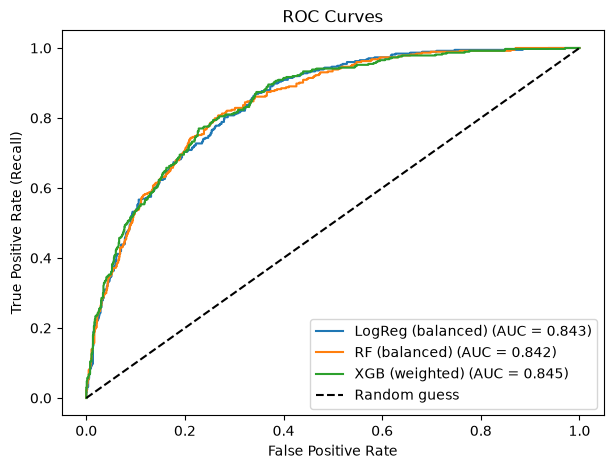

In [62]:
plt.figure(figsize=(7, 5))
for name, proba in [('LogReg (balanced)', y_proba_bal),
                    ('RF (balanced)', y_proba_rf_bal),
                    ('XGB (weighted)', y_proba_xgb_bal)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.title('ROC Curves')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend()
plt.show()

**Insight:** The ROC curves of Logistic Regression, Random Forest and XGBoost almost overlap (AUC 0.843, 0.842 and 0.845). All three models rank churners about equally well, so on this dataset a complex model brings almost no gain over simple Logistic Regression. The differences in recall and precision between the models come mostly from class weights and the decision threshold, not from the algorithm.

##### **10. Final Pipeline and Hyperparameter Tuning**

In [63]:
xgb_pipe = Pipeline([
    ('preprocess', preprocessor),
    ('model', XGBClassifier(
        n_estimators=200, max_depth=4, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
        eval_metric='logloss', random_state=42, n_jobs=-1
    ))
])

In [64]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(xgb_pipe, X_train, y_train, cv=cv, scoring='roc_auc')

print(f"CV ROC-AUC (before tuning): {cv_scores.mean():.3f} +/- {cv_scores.std():.3f}")

CV ROC-AUC (before tuning): 0.847 +/- 0.011


In [65]:
param_dist = {
    'model__n_estimators': [100, 200, 300 ,400],
    'model__max_depth': [3, 4, 5, 6],
    'model__learning_rate': [0.01, 0.03, 0.04, 0.1],
    'model__subsample': [0.7, 0.8, 0.9, 1.0],
    'model__colsample_bytree': [0.6, 0.8, 1.0],
    'model__min_child_weight': [1, 3, 5],
}

In [66]:
search = RandomizedSearchCV(
    xgb_pipe,
    param_distributions=param_dist,
    n_iter=20,
    scoring='roc_auc',
    cv=cv,
    random_state =42,
    n_jobs=1,
    verbose=1
)
search.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__colsample_bytree': [0.6, 0.8, ...], 'model__learning_rate': [0.01, 0.03, ...], 'model__max_depth': [3, 4, ...], 'model__min_child_weight': [1, 3, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosi

In [67]:
print("Best settings:", search.best_params_)

Best settings: {'model__subsample': 0.7, 'model__n_estimators': 400, 'model__min_child_weight': 5, 'model__max_depth': 4, 'model__learning_rate': 0.01, 'model__colsample_bytree': 0.8}


In [68]:
print(f"Best CV ROC-AUC (after tuning): {search.best_score_:.3f}")

Best CV ROC-AUC (after tuning): 0.850


In [69]:
for name, value in search.best_params_.items():
    print(name, "=", value)

model__subsample = 0.7
model__n_estimators = 400
model__min_child_weight = 5
model__max_depth = 4
model__learning_rate = 0.01
model__colsample_bytree = 0.8


**Insight:** Randomized search over 20 settings with 5-fold cross-validation improved the CV ROC-AUC only from 0.847 to 0.850. This gain of 0.003 is smaller than the fold-to-fold variation (+/- 0.011), so hyperparameter tuning made no meaningful difference. The best settings use a small learning rate (0.01) with more trees (400), shallow trees (max_depth 4) and a higher min_child_weight (5), which means the model learns slowly and cautiously. On this dataset the biggest gains came from handling class imbalance, not from tuning.

##### **11. Threshold Tuning**

In [70]:
best_model = search.best_estimator_
oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

In [71]:
rows = []
for t in np.arange(0.2, 0.81, 0.05):
    pred_t = (oof_proba >= t).astype(int)
    rows.append({
        'Threshold': round(t, 2),
        'Precision': precision_score(y_train, pred_t, zero_division=0),
        'Recall': recall_score(y_train, pred_t),
        'F1': f1_score(y_train, pred_t),
    })

threshold_df = pd.DataFrame(rows).round(3)
threshold_df

,Threshold,Precision,Recall,F1
0,0.20,0.388,0.957,0.552
1,0.25,0.407,0.935,0.567
2,0.30,0.432,0.914,0.587
3,0.35,0.457,0.892,0.604
4,0.40,0.478,0.864,0.615
5,0.45,0.502,0.833,0.627
6,0.50,0.524,0.800,0.633
7,0.55,0.558,0.752,0.640
8,0.60,0.585,0.694,0.635
9,0.65,0.624,0.637,0.631


**Insight:** As the threshold rises, precision increases (0.388 to 0.721) while recall falls (0.957 to 0.348). F1 peaks at a threshold of 0.55 (F1 = 0.640, recall = 0.752). I chose 0.55 because it keeps recall above 0.75, so most churners are still caught, while giving the best precision/recall balance. The threshold was chosen on out-of-fold training predictions, so the test set stays untouched.

##### **12. Final Evaluation**

In [72]:
final_threshold = 0.55

In [73]:
y_proba_final = best_model.predict_proba(X_test)[:, 1]
y_pred_final = (y_proba_final >= final_threshold).astype(int)

In [74]:
print(classification_report(y_test, y_pred_final))
print(confusion_matrix(y_test, y_pred_final))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_final):.3f}")

              precision    recall  f1-score   support

           0       0.90      0.77      0.83      1035
           1       0.54      0.76      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409

[[793 242]
 [ 89 285]]
ROC-AUC: 0.848


**Insight:** On the untouched test set, the final tuned XGBoost pipeline with a threshold of 0.55 reaches a recall of 0.76 and a precision of 0.54 for churners (F1 = 0.63, ROC-AUC = 0.848). It catches 285 of the 374 churners and misses 89, compared with 177 missed by the baseline Logistic Regression (recall 0.53).The test results are close to the out-of-fold training estimates (recall 0.75, precision 0.56), which suggests the model generalises well and is not badly overfitted. About one in two customers it flags will actually leave, which is acceptable when losing a customer costs more than a retention offer.

In [75]:
final_df = pd.DataFrame(results + [evaluate('XGB (tuned, thr 0.55)', y_test, y_pred_final, y_proba_final)]).round(3)
final_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,LogReg (plain),0.803,0.661,0.527,0.586,0.843
1,LogReg (balanced),0.740,0.507,0.797,0.620,0.843
2,RF (plain),0.799,0.662,0.497,0.568,0.842
3,RF (balanced),0.751,0.520,0.799,0.630,0.842
4,XGB (plain),0.805,0.672,0.516,0.584,0.845
5,XGB (weighted),0.756,0.527,0.789,0.632,0.845
6,"XGB (tuned, thr 0.55)",0.765,0.541,0.762,0.633,0.848


##### **13.  Feature Importance**

In [76]:
pre = best_model.named_steps['preprocess']
xgb_model = best_model.named_steps['model']

feature_names = [n.split('__', 1)[1] for n in pre.get_feature_names_out()]
importance = pd.Series(xgb_model.feature_importances_, index=feature_names).sort_values(ascending=False)
importance.head(10)

Contract_Month-to-month        0.316805
InternetService_Fiber optic    0.060961
OnlineSecurity_No              0.053959
Contract_Two year              0.048898
TechSupport_No                 0.046295
Contract_One year              0.030398
TenureGroup_0-12               0.029117
InternetService_DSL            0.021308
tenure                         0.019251
StreamingMovies_Yes            0.019177
dtype: float32

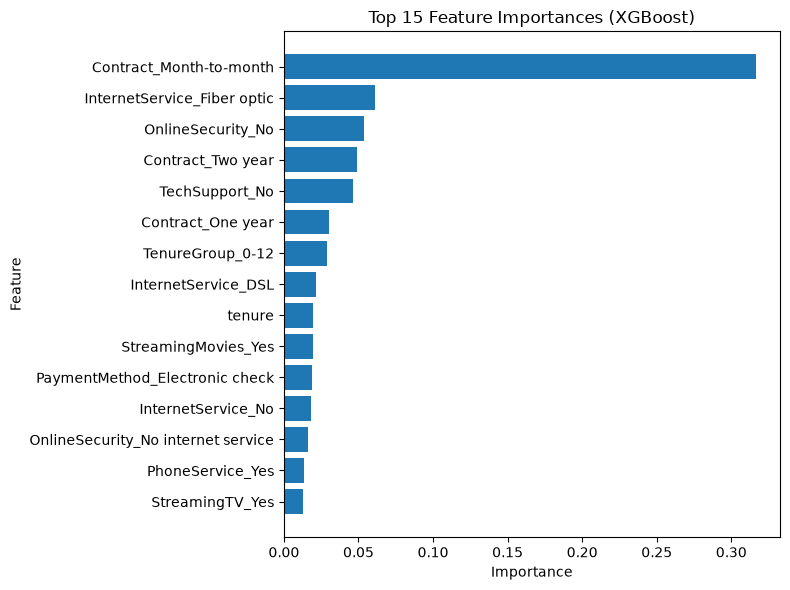

In [77]:
top = importance.head(15)[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values)
plt.title('Top 15 Feature Importances (XGBoost)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

 **Insight:** The most important feature is Contract_Month-to-month. After it, the model relies mainly on the contract type (one-year and two-year contracts), the internet service type (fiber optic in particular), the lack of online security and tech support, and short tenure (the engineered TenureGroup_0-12 feature ranks in the top 15). Service and billing details such as streaming and phone service matter much less. These drivers match the patterns found during EDA.

In [78]:
for col in ['Contract', 'InternetService', 'OnlineSecurity', 'TechSupport', 'TenureGroup']:
    print(df.groupby(col, observed=True)['Churn'].mean().round(3), "\n")

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64 

InternetService
DSL            0.190
Fiber optic    0.419
No             0.074
Name: Churn, dtype: float64 

OnlineSecurity
No                     0.418
No internet service    0.074
Yes                    0.146
Name: Churn, dtype: float64 

TechSupport
No                     0.416
No internet service    0.074
Yes                    0.152
Name: Churn, dtype: float64 

TenureGroup
0-12     0.474
13-24    0.287
25-36    0.216
37-48    0.190
49-60    0.144
61-72    0.066
Name: Churn, dtype: float64 



**Insight:** Churn rates by group confirm what the model learned. Month-to-month customers churn at 42.7% compared with 11.3% (one-year) and 2.8% (two-year). Fiber optic customers churn at 41.9% versus 19.0% for DSL. Customers without online security (41.8%) or tech support (41.6%) churn about three times as often as those with them (14.6% and 15.2%). Churn falls steadily with tenure, from 47.4% in the first 12 months to 6.6% after 5 years.|

##### **14. Save Model**

In [79]:
os.makedirs('../models', exist_ok=True)

bundle = {
    'pipeline': best_model,
    'threshold': final_threshold,
    'columns': X_train.columns.tolist(),
}
joblib.dump(bundle, '../models/churn_model.pkl')

['../models/churn_model.pkl']

In [80]:
loaded = joblib.load('../models/churn_model.pkl')
print(loaded['threshold'])
loaded['pipeline'].predict_proba(X_test.head(3))[:, 1]

0.55


array([0.0511163 , 0.8828796 , 0.17534499], dtype=float32)

##### **15. Business Recommendations**

Based on the churn rates and the model's most important features:

1. **Month-to-month customers:** They churn at 42.7%, versus 11.3% on one-year and 2.8% on two-year contracts. Offer discounts or incentives to move them to longer contracts.
2. **New customers (first 12 months):** Churn is 47.4% in this group. Strengthen onboarding and run check-ins during the first year.
3. **Fiber optic customers:** They churn at 41.9% versus 19.0% for DSL. Investigate service quality, pricing and competitor offers on fiber plans.
4. **Customers without Online Security or Tech Support:** Churn is about 42% versus about 15% for those who have them. Promote or bundle these services, for example with a free trial.
5. **Targeted outreach:** Contact customers flagged by the model (threshold 0.55) first. The model catches about 76% of churners, and about one in two flagged customers will actually leave.

**Note:** These are associations found in the data and the model, not proven causes. A/B testing of retention offers would be needed to confirm which actions actually reduce churn.